# 第190章: 変数変換とヤコビアン — 厳密な尤度を計算する

## Change of Variables and the Jacobian Determinant

---

### このノートブックの位置づけ

ここまで学んだ生成モデルは、**尤度を厳密には計算できませんでした**。

| モデル | 尤度 | ノートブック |
|---|---|---|
| VAE | 下界（ELBO）しか出ない | 35-36 |
| GAN | そもそも尤度を定義しない | 39-40 |
| 拡散モデル | 下界（変分下界） | 41-45 |
| 自己回帰モデル | **厳密**（ただし逐次生成） | 46・145 |
| **正規化フロー** | **厳密**（かつ並列生成可能） | **本章から** |

正規化フロー（Normalizing Flow）は「厳密な対数尤度」と「高速なサンプリング」を
同時に狙う生成モデルです。その土台はたった1本の式 — **変数変換の公式** です。

$$p_X(x) = p_Z(f(x)) \left| \det \frac{\partial f}{\partial x} \right|$$

本章ではこの式を**導出せずに済ませず**、1次元で数値検証し、多次元で
「ヤコビアン行列式 = 体積の伸び率」として可視化し、最後に**実際に 1 次元フローを
最尤学習して厳密な対数尤度を出す**ところまでやります。

> **なぜ 191（RealNVP）の前にこの章が必要か**
> フローの設計は全部「行列式を安く計算する」ための工夫です。
> 本章で**行列式が高いこと**と**三角行列なら安いこと**を実測しておくと、
> 191 のカップリング層が「天才的なトリック」ではなく
> 「制約から必然的に出てくる形」として読めます。

### 学習目標

- [ ] 1次元の変数変換の公式を導出し、ヒストグラムと理論密度の一致で数値検証できる
- [ ] ヤコビアン行列式が「微小体積の伸び率」であることを 2 次元で面積として確認できる
- [ ] 変換の合成に対して $\log|\det|$ が**足し算**になることを示せる
- [ ] 可逆でない写像では変数変換の公式が使えない理由を具体例で説明できる
- [ ] 一般の行列式が $O(d^3)$、三角行列なら $O(d)$ であることを**実測**できる
- [ ] 単調性を保証した 1 次元フローを実装し、**厳密な NLL** を真の下限と比べられる
- [ ] サンプリングが逆写像であることを理解し、数値的な逆写像の落とし穴を踏める

### 前提知識

| ノートブック | トピック |
|---|---|
| 31 | 最尤推定（負の対数尤度の最小化） |
| 33 | 混合ガウスモデル（本章の目標分布に使う） |
| 47 | 混合密度ネットワーク（「厳密な尤度」の味を既に見ている） |
| 35 | VAE（ELBO = 下界しか出ないことの対比） |
| 線形代数 | 行列式、ヤコビアン行列 |

**難易度**: ★★★☆☆ | **所要時間**: 90-120分

> ⏱ **実行時間**: CPU で約1分です（行列式のベンチマークが大半）。

## 目次

1. [環境セットアップ](#setup)
2. [1次元の変数変換 — 公式を数値検証する](#onedim)
3. [多次元 — ヤコビアン行列式は「体積の伸び率」](#jacobian)
4. [可逆でないと使えない](#invertible)
5. [行列式の計算コスト — フロー設計の制約](#cost)
6. [1次元フローを最尤で学習する](#train)
7. [サンプリング = 逆写像](#sampling)
8. [まとめとチートシート](#summary)
9. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)
print("numpy:", np.__version__)

torch: 2.9.1
numpy: 2.2.6


<a id="onedim"></a>
## 2. 1次元の変数変換 — 公式を数値検証する

### 導出

$z \sim p_Z$ を単調増加な写像 $g$ で $x = g(z)$ に変換します。
累積分布関数で考えると、$g$ が単調増加なら

$$F_X(x) = P(X \le x) = P(g(Z) \le x) = P(Z \le g^{-1}(x)) = F_Z(g^{-1}(x))$$

両辺を $x$ で微分します。$f := g^{-1}$ と書くと

$$p_X(x) = p_Z(f(x)) \cdot \left| \frac{df}{dx} \right|$$

絶対値は $g$ が単調減少の場合（$f' < 0$）も含めるためです。密度は非負でなければ
いけませんが、微分は符号を持ちうるからです。

$g$ の側で書けば、$\frac{df}{dx} = 1 / g'(z)$ なので

$$p_X(x) = \frac{p_Z(z)}{|g'(z)|}, \quad z = f(x)$$

**直感**: $g$ が区間を $|g'|$ 倍に引き伸ばすなら、同じ確率質量が広い区間に
薄く広がるので、密度は $|g'|$ で割られます。

### 数値検証

$z \sim \mathcal{N}(0,1)$、$x = g(z) = 2z + 1 + 0.5 z^3$ でやります。
$g'(z) = 2 + 1.5 z^2 > 0$ なので**狭義単調増加 = 可逆**です。

$g^{-1}$ は閉形式で書けますが（3次方程式）、ここでは**ニュートン法**で解きます。
$g$ が単調で $g'$ が下から $2$ で押さえられているので、ニュートン法は素直に収束します。

In [2]:
# ============================================================
# 1次元の変数変換: x = g(z) = 2z + 1 + 0.5 z^3
# ============================================================

def g(z):
    return 2.0 * z + 1.0 + 0.5 * z**3

def g_prime(z):
    return 2.0 + 1.5 * z**2

def g_inverse(x, iters=60):
    # g は単調増加・g' >= 2 なのでニュートン法で安全に解ける
    z = np.zeros_like(x)
    for _ in range(iters):
        z = z - (g(z) - x) / g_prime(z)
    return z

def normal_pdf(z):
    return np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

def px_theory(x):
    # p_X(x) = p_Z(g^{-1}(x)) / |g'(g^{-1}(x))|
    z = g_inverse(x)
    return normal_pdf(z) / np.abs(g_prime(z))

# サンプルを変換してヒストグラムを作る
rng = np.random.default_rng(SEED)
z_samples = rng.standard_normal(400_000)
x_samples = g(z_samples)

# 図示用のグリッドと、積分用のグリッドは分ける。
# g は 3 次なので裾が長く、z in [-5, 5] は x in [-71, 74] まで広がる。
# 図の範囲（[-14, 16]）で積分すると裾を取りこぼして 1 に届かない。
x_plot = np.linspace(-14, 16, 1501)
x_int = np.linspace(-80.0, 82.0, 40001)

# 逆写像の精度チェック
z_back = g_inverse(x_plot)
inv_resid = np.abs(g(z_back) - x_plot).max()
print(f"逆写像の最大残差: {inv_resid:.2e}")

# ヒストグラムと理論密度の一致を測る
bins = np.linspace(-14, 16, 121)
hist, edges = np.histogram(x_samples, bins=bins, density=True)
centers = 0.5 * (edges[:-1] + edges[1:])
theory = px_theory(centers)
err = np.abs(hist - theory)
print(f"ヒストグラム vs 理論密度: 平均誤差 {err.mean():.5f} / 最大誤差 {err.max():.5f}")

# 密度の正規化（積分が 1 になるか）
integral = np.trapezoid(px_theory(x_int), x_int)
integral_truncated = np.trapezoid(px_theory(x_plot), x_plot)
print(f"理論密度の積分（広い範囲）: {integral:.5f}  (1 になるべき)")
print(f"理論密度の積分（図の範囲）: {integral_truncated:.5f}  <- 裾の取りこぼし")

# 「変換しても密度をそのまま使う」= ヤコビアンを忘れた場合
wrong_int = normal_pdf(g_inverse(x_int))
wrong = normal_pdf(g_inverse(x_plot))      # 図示用
wrong_integral = np.trapezoid(wrong_int, x_int)
print()
print(f"ヤコビアンを忘れた密度の積分: {wrong_integral:.5f}  <- 1 にならない")
print(f"  （理論値 E[g'(Z)] = 2 + 1.5 Var(Z) = {2 + 1.5:.1f}。"
      f"密度でないものを密度と呼んでいる）")

逆写像の最大残差: 3.55e-15
ヒストグラム vs 理論密度: 平均誤差 0.00039 / 最大誤差 0.00320
理論密度の積分（広い範囲）: 1.00000  (1 になるべき)
理論密度の積分（図の範囲）: 0.99266  <- 裾の取りこぼし

ヤコビアンを忘れた密度の積分: 3.49999  <- 1 にならない
  （理論値 E[g'(Z)] = 2 + 1.5 Var(Z) = 3.5。密度でないものを密度と呼んでいる）


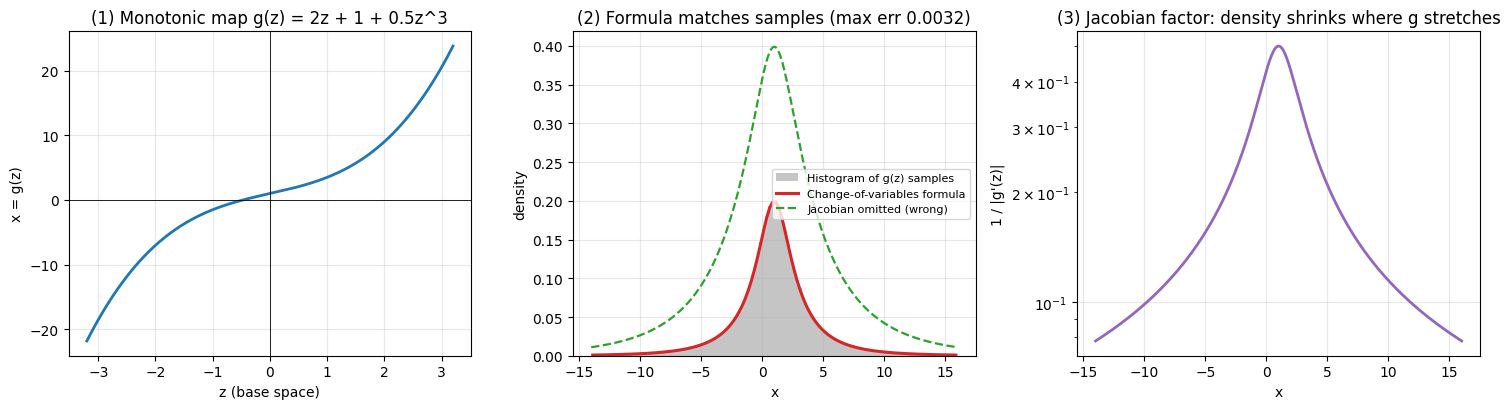

In [3]:
# ============================================================
# 図: 変数変換の 3 つの見方
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (1) 写像そのもの
zz = np.linspace(-3.2, 3.2, 400)
axes[0].plot(zz, g(zz), lw=2, color="tab:blue")
axes[0].set_xlabel("z (base space)")
axes[0].set_ylabel("x = g(z)")
axes[0].set_title("(1) Monotonic map g(z) = 2z + 1 + 0.5z^3")
axes[0].axhline(0, color="k", lw=0.6)
axes[0].axvline(0, color="k", lw=0.6)

# (2) ヒストグラム vs 理論
axes[1].hist(x_samples, bins=bins, density=True, alpha=0.45,
             color="tab:gray", label="Histogram of g(z) samples")
axes[1].plot(centers, theory, lw=2.2, color="tab:red",
             label="Change-of-variables formula")
axes[1].plot(x_plot, wrong, lw=1.6, ls="--", color="tab:green",
             label="Jacobian omitted (wrong)")
axes[1].set_xlabel("x")
axes[1].set_ylabel("density")
axes[1].set_title(f"(2) Formula matches samples (max err {err.max():.4f})")
axes[1].legend(fontsize=8)

# (3) ヤコビアン因子そのもの
axes[2].plot(x_plot, 1.0 / np.abs(g_prime(g_inverse(x_plot))), lw=2, color="tab:purple")
axes[2].set_xlabel("x")
axes[2].set_ylabel("1 / |g'(z)|")
axes[2].set_title("(3) Jacobian factor: density shrinks where g stretches")
axes[2].set_yscale("log")

plt.tight_layout()
plt.show()

### 読み取れること

- 中央の図で、ヒストグラム（実サンプル）と公式（赤）が**最大誤差 0.0032**で
  一致します。公式は正しい。
- 緑の破線は**ヤコビアンを掛け忘れた**ときの密度です。形が違うだけでなく、
  **積分が 3.5 になります**。これは偶然ではありません。
  $\int p_Z(f(x))\,dx = \int p_Z(z) g'(z)\,dz = \mathbb{E}[g'(Z)]
  = 2 + 1.5\,\mathrm{Var}(Z) = 3.5$ です。
  つまり「密度でないもの」を密度として使っていることになります。
  学習に使うと、最大化できる上限がない壊れた目的関数になります（クイズ Q1）。
- 🔧 **数値積分の落とし穴（2つ踏みました）**:
  (a) $g$ は 3 次なので裾が長く、図の範囲 $[-14, 16]$ で積分すると 0.9927 しか
  出ません。$z \in [-5,5]$ は $x \in [-71, 74]$ に広がります。**図示用と積分用の
  グリッドは別物**です。
  (b) 第 4 節の $z^2$ では密度が $x \to 0$ で $x^{-1/2}$ 発散するので、
  $x$ の等間隔グリッドに台形則を当てると 9.6% 過大評価します（1.096 が出る）。
  $x = u^2$ と置換すると被積分関数が $p_Z(u) + p_Z(-u)$ になり特異点が消えます。
- 右の図は $1/|g'|$ です。$|z|$ が大きいところで $g$ は 3 次で急激に伸びるので、
  そこでは密度が強く圧縮されています。これが $x$ の分布の裾が薄い理由です。

<a id="jacobian"></a>
## 3. 多次元 — ヤコビアン行列式は「体積の伸び率」

$d$ 次元では微分がヤコビアン行列になります。

$$J_f(x) = \frac{\partial f}{\partial x} \in \mathbb{R}^{d \times d}, \qquad
p_X(x) = p_Z(f(x)) \, |\det J_f(x)|$$

$|\det J|$ が**微小体積の伸び率**であることを、アフィン写像 $x = Az + b$ で
確かめます。アフィン写像ならヤコビアンは $A$ で、位置によらず一定です。

3通りの方法で同じ数が出るはずです。

1. $\det A$ を**手で**（2x2 公式 $ad - bc$）
2. `numpy.linalg.det`
3. **単位正方形の像の面積**をモンテカルロで測る

さらに、$z \sim \mathcal{N}(0, I)$ なら $x = Az + b$ の共分散は $AA^\top$ に
なるはずなので、それも確かめます。

In [4]:
# ============================================================
# 2次元アフィン写像のヤコビアン行列式 = 面積の伸び率
# ============================================================

A = np.array([[2.0, 0.5],
              [0.3, 1.5]])
b = np.array([1.0, -0.5])

det_manual = A[0, 0] * A[1, 1] - A[0, 1] * A[1, 0]
det_numpy = np.linalg.det(A)
print(f"(1) 手計算 ad - bc      : {det_manual:.4f}")
print(f"(2) numpy.linalg.det    : {det_numpy:.4f}")

# (3) 単位正方形の像の面積をモンテカルロで測る
#     単位正方形 [0,1]^2 を A で写した平行四辺形の面積を、
#     その外接矩形に一様点を撒いて「内側の割合 x 外接矩形の面積」で推定する
corners = np.array([[0, 0], [1, 0], [1, 1], [0, 1]], dtype=float)
img_corners = corners @ A.T
lo, hi = img_corners.min(0) - 0.1, img_corners.max(0) + 0.1
box_area = np.prod(hi - lo)

rng2 = np.random.default_rng(1)
pts = rng2.uniform(lo, hi, size=(2_000_000, 2))
# 逆写像で単位正方形に戻して内外判定する（A は可逆）
pre = pts @ np.linalg.inv(A).T
inside = np.all((pre >= 0) & (pre <= 1), axis=1)
area_mc = inside.mean() * box_area
print(f"(3) 単位正方形の像の面積: {area_mc:.4f}  (モンテカルロ 2e6 点)")
print()

# z ~ N(0, I) -> x = Az + b の共分散は A A^T
z2 = rng2.standard_normal((400_000, 2))
x2 = z2 @ A.T + b
cov_emp = np.cov(x2.T)
cov_theory = A @ A.T
print("標本共分散:")
print(np.round(cov_emp, 4))
print("理論 A A^T:")
print(np.round(cov_theory, 4))
print(f"最大差: {np.abs(cov_emp - cov_theory).max():.4f}")

(1) 手計算 ad - bc      : 2.8500
(2) numpy.linalg.det    : 2.8500
(3) 単位正方形の像の面積: 2.8487  (モンテカルロ 2e6 点)

標本共分散:
[[4.2479 1.3454]
 [1.3454 2.348 ]]
理論 A A^T:
[[4.25 1.35]
 [1.35 2.34]]
最大差: 0.0080


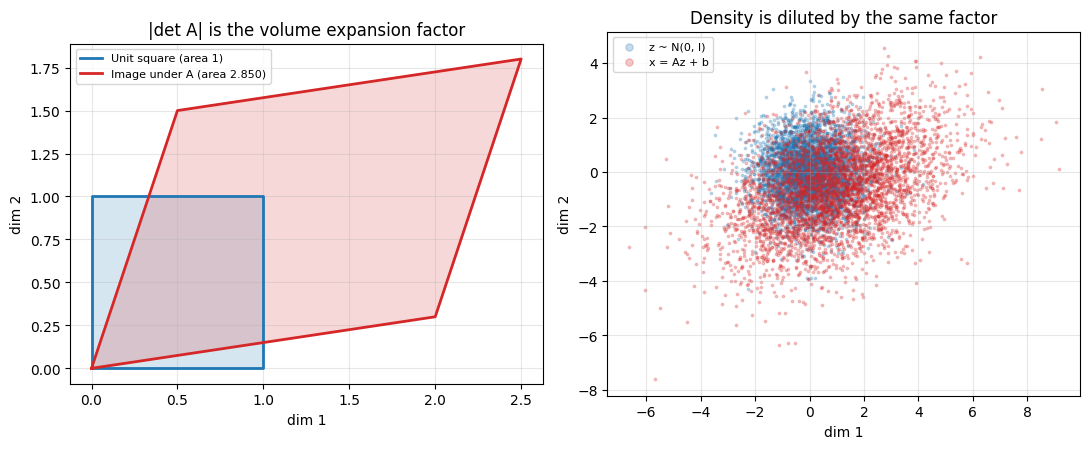

In [5]:
# ============================================================
# 図: 単位正方形がどう写るか
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

# 単位正方形とその像
sq = np.vstack([corners, corners[:1]])
img = np.vstack([img_corners, img_corners[:1]])
axes[0].plot(sq[:, 0], sq[:, 1], lw=2, color="tab:blue", label="Unit square (area 1)")
axes[0].fill(sq[:, 0], sq[:, 1], color="tab:blue", alpha=0.18)
axes[0].plot(img[:, 0], img[:, 1], lw=2, color="tab:red",
             label=f"Image under A (area {det_manual:.3f})")
axes[0].fill(img[:, 0], img[:, 1], color="tab:red", alpha=0.18)
axes[0].set_aspect("equal")
axes[0].set_xlabel("dim 1")
axes[0].set_ylabel("dim 2")
axes[0].set_title("|det A| is the volume expansion factor")
axes[0].legend(fontsize=8)

# サンプルの散布図
sub = rng2.choice(len(x2), 4000, replace=False)
axes[1].scatter(z2[sub, 0], z2[sub, 1], s=3, alpha=0.25,
                color="tab:blue", label="z ~ N(0, I)")
axes[1].scatter(x2[sub, 0], x2[sub, 1], s=3, alpha=0.25,
                color="tab:red", label="x = Az + b")
axes[1].set_aspect("equal")
axes[1].set_xlabel("dim 1")
axes[1].set_ylabel("dim 2")
axes[1].set_title("Density is diluted by the same factor")
axes[1].legend(fontsize=8, markerscale=3)

plt.tight_layout()
plt.show()

### 合成は $\log|\det|$ の足し算になる

フローは「簡単な可逆変換を何層も重ねる」モデルです。合成写像
$f = f_K \circ \cdots \circ f_1$ のヤコビアンは連鎖律で行列の積になり、
行列式は積に分配されるので

$$\log |\det J_f| = \sum_{k=1}^{K} \log |\det J_{f_k}|$$

**足し算**になります。これがフローを深くできる理由です。層ごとに
$\log|\det|$ を計算して足すだけでよく、巨大な行列を一度も作りません。

これを実測で確かめます。

In [6]:
# ============================================================
# 合成すると log|det| は足し算になる
# ============================================================

rng3 = np.random.default_rng(7)
d = 6
mats = [rng3.normal(size=(d, d)) + np.eye(d) * 2.0 for _ in range(5)]

# (a) 先に全部掛けてから 1 回 logdet を取る
prod = np.eye(d)
for M in mats:
    prod = M @ prod
sign_all, logdet_all = np.linalg.slogdet(prod)

# (b) 層ごとに logdet を取って足す
logdet_sum = sum(np.linalg.slogdet(M)[1] for M in mats)

print(f"(a) 合成行列の log|det|      : {logdet_all:.10f}")
print(f"(b) 層ごとの log|det| の和   : {logdet_sum:.10f}")
print(f"    差                      : {abs(logdet_all - logdet_sum):.2e}")
print()
print("-> フローは (b) で計算する。層を増やしても行列積を作る必要がない。")

(a) 合成行列の log|det|      : 17.7842920262
(b) 層ごとの log|det| の和   : 17.7842920262
    差                      : 7.46e-14

-> フローは (b) で計算する。層を増やしても行列積を作る必要がない。


<a id="invertible"></a>
## 4. 可逆でないと使えない

変数変換の公式は「$x$ に対応する $z$ が**ただ1つ**」を前提にしています。
可逆でない写像だと、1つの $x$ に複数の $z$ が対応し、密度はそれらの**和**に
なります。

$$p_X(x) = \sum_{z_i : g(z_i) = x} \frac{p_Z(z_i)}{|g'(z_i)|}$$

$x = g(z) = z^2$ で確かめます。$x > 0$ に対して $z = \pm\sqrt{x}$ の 2 つが
対応します。片方だけ使うと密度が**半分**になります。

In [7]:
# ============================================================
# 可逆でない写像: x = z^2
# ============================================================

z_s = rng.standard_normal(400_000)
x_s = z_s**2

xs = np.linspace(1e-4, 9.0, 1200)      # 図示用

# 片方の原像だけ使った（誤った）密度
one_branch = normal_pdf(np.sqrt(xs)) / np.abs(2 * np.sqrt(xs))
# 両方の原像を足した（正しい）密度 = カイ二乗(1) 分布
both_branches = (normal_pdf(np.sqrt(xs)) + normal_pdf(-np.sqrt(xs))) / np.abs(2 * np.sqrt(xs))

# 積分は x = u^2 と置換して求める。
# p_X(x) は x -> 0 で x^{-1/2} のように発散するので、
# x で等間隔に台形則を当てると左端で大きく過大評価する（ここを素朴にやると 1.096 が出る）。
#   dx = 2u du なので  p_X(u^2) * 2u = p_Z(u) + p_Z(-u)
# つまり置換後の被積分関数は特異点を持たない。
u = np.linspace(0.0, 12.0, 60001)
int_one = np.trapezoid(normal_pdf(u), u)                      # 片方の原像だけ
int_both = np.trapezoid(normal_pdf(u) + normal_pdf(-u), u)     # 両方の原像

print(f"片方の原像だけ: 積分 {int_one:.4f}  <- 0.5 になる")
print(f"両方の原像の和: 積分 {int_both:.4f}  <- 1 になる")
print()
print("置換前のグリッドで素朴に台形則を当てると:")
print(f"  片方 {np.trapezoid(one_branch, xs):.4f} / 両方 "
      f"{np.trapezoid(both_branches, xs):.4f}  <- 特異点のせいで過大評価")
print()
print("x = 4.0 に対応する z:", np.sqrt(4.0), "と", -np.sqrt(4.0))
print("-> フローの各層は可逆でなければならない。これが設計上の最大の制約。")

片方の原像だけ: 積分 0.5000  <- 0.5 になる
両方の原像の和: 積分 1.0000  <- 1 になる

置換前のグリッドで素朴に台形則を当てると:
  片方 0.5480 / 両方 1.0960  <- 特異点のせいで過大評価

x = 4.0 に対応する z: 2.0 と -2.0
-> フローの各層は可逆でなければならない。これが設計上の最大の制約。


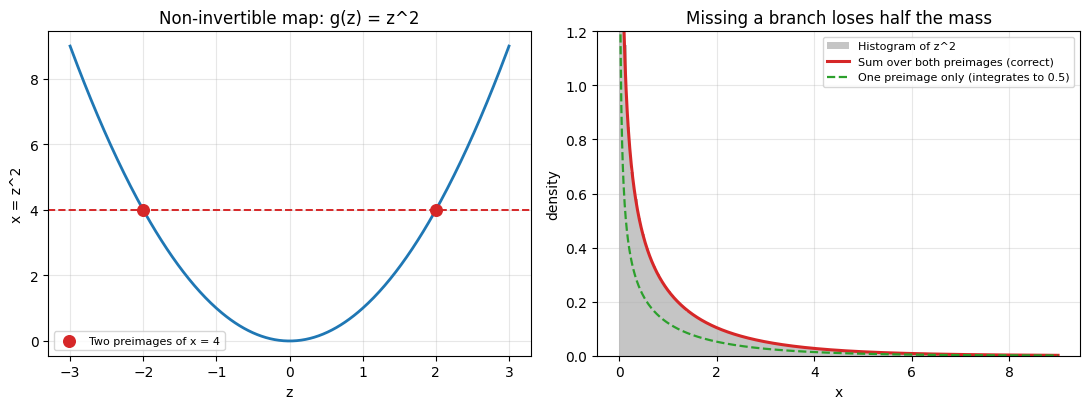

In [8]:
# ============================================================
# 図: 可逆でない写像では原像が複数ある
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

zz2 = np.linspace(-3, 3, 400)
axes[0].plot(zz2, zz2**2, lw=2, color="tab:blue")
axes[0].axhline(4.0, color="tab:red", lw=1.4, ls="--")
axes[0].scatter([-2, 2], [4, 4], s=70, color="tab:red", zorder=5,
                label="Two preimages of x = 4")
axes[0].set_xlabel("z")
axes[0].set_ylabel("x = z^2")
axes[0].set_title("Non-invertible map: g(z) = z^2")
axes[0].legend(fontsize=8)

axes[1].hist(x_s, bins=np.linspace(0, 9, 120), density=True, alpha=0.45,
             color="tab:gray", label="Histogram of z^2")
axes[1].plot(xs, both_branches, lw=2.2, color="tab:red",
             label="Sum over both preimages (correct)")
axes[1].plot(xs, one_branch, lw=1.6, ls="--", color="tab:green",
             label="One preimage only (integrates to 0.5)")
axes[1].set_ylim(0, 1.2)
axes[1].set_xlabel("x")
axes[1].set_ylabel("density")
axes[1].set_title("Missing a branch loses half the mass")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

<a id="cost"></a>
## 5. 行列式の計算コスト — フロー設計の制約

ここがフロー設計の核心です。一般の $d \times d$ 行列の行列式は LU 分解を経由して
$O(d^3)$ です。一方、**三角行列**なら対角成分の積なので $O(d)$ です。

$$\det T = \prod_{i=1}^{d} T_{ii} \quad (T \text{ が三角行列})$$

フローの中身は「$d$ が大きくても $\log|\det|$ が安く出る変換」を探す営みです。
三角ヤコビアンを得る代表的な方法が 191 で扱う**カップリング層**です。

実測します。**ウォームアップを入れる**のを忘れないでください（最初の呼び出しには
ライブラリの初期化コストが乗ります）。

In [9]:
# ============================================================
# 行列式の計算コスト: 一般行列 vs 三角行列
# ============================================================

def bench(fn, reps):
    for _ in range(3):      # ウォームアップ（初回はライブラリ初期化で遅い）
        fn()
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps

dims = [32, 128, 512, 1024, 2048]
rows = []
for dd in dims:
    M = torch.randn(dd, dd)
    T = torch.tril(torch.randn(dd, dd)) + torch.eye(dd) * dd   # 下三角（対角は正）
    reps = 50 if dd <= 512 else 10
    t_full = bench(lambda: torch.linalg.slogdet(M), reps)
    t_tri = bench(lambda: torch.diagonal(T).abs().log().sum(), reps)
    rows.append((dd, t_full, t_tri))
    print(f"d={dd:5d}: slogdet {t_full*1e6:9.1f} us   "
          f"対角積 {t_tri*1e6:7.1f} us   比 {t_full/t_tri:8.1f}x")

print()
print("slogdet の局所的なスケーリング指数（連続する 2 点の両対数傾き）:")
slopes = []
for i in range(1, len(rows)):
    d0, t0, _ = rows[i - 1]
    d1, t1, _ = rows[i]
    s = np.log(t1 / t0) / np.log(d1 / d0)
    slopes.append((d0, d1, s))
    print(f"  d {d0:5d} -> {d1:5d}: 時間 {t1/t0:5.2f} 倍  => 傾き {s:.2f}")
print(f"\n理論は 3。最大の d での実測は {slopes[-1][2]:.2f}。")

d=   32: slogdet      13.1 us   対角積     2.2 us   比      6.0x
d=  128: slogdet      42.2 us   対角積     2.5 us   比     16.6x
d=  512: slogdet     533.7 us   対角積     2.9 us   比    181.5x


d= 1024: slogdet    2444.1 us   対角積     4.0 us   比    612.9x


d= 2048: slogdet   11379.9 us   対角積     5.9 us   比   1943.9x

slogdet の局所的なスケーリング指数（連続する 2 点の両対数傾き）:
  d    32 ->   128: 時間  3.22 倍  => 傾き 0.84
  d   128 ->   512: 時間 12.65 倍  => 傾き 1.83
  d   512 ->  1024: 時間  4.58 倍  => 傾き 2.20
  d  1024 ->  2048: 時間  4.66 倍  => 傾き 2.22

理論は 3。最大の d での実測は 2.22。


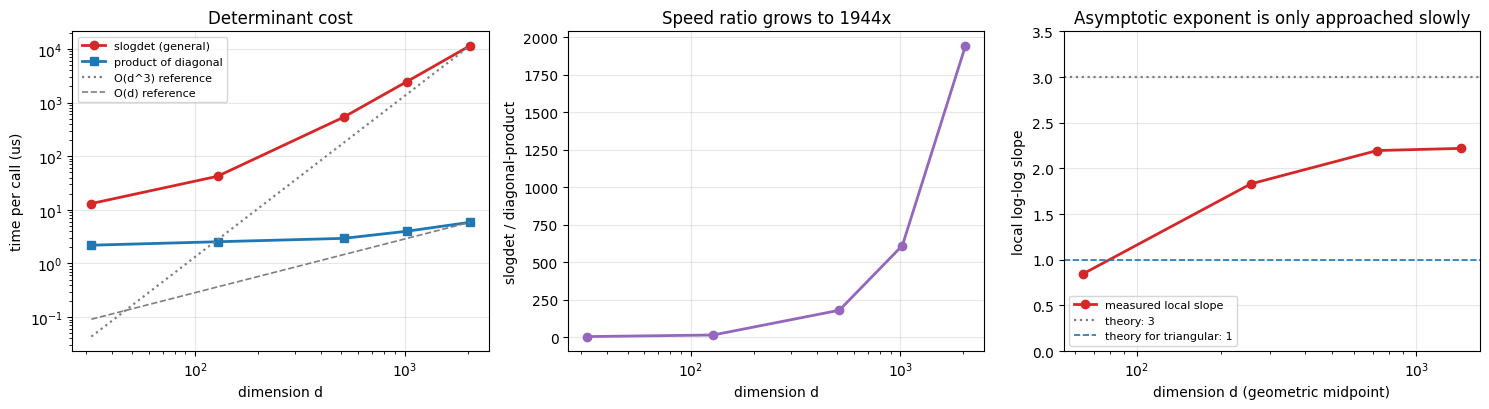

In [10]:
# ============================================================
# 図: 行列式の計算コスト
# ============================================================

ds = np.array([r[0] for r in rows], dtype=float)
t_full_arr = np.array([r[1] for r in rows]) * 1e6
t_tri_arr = np.array([r[2] for r in rows]) * 1e6

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].loglog(ds, t_full_arr, "o-", lw=2, color="tab:red", label="slogdet (general)")
axes[0].loglog(ds, t_tri_arr, "s-", lw=2, color="tab:blue", label="product of diagonal")
ref = t_full_arr[-1] * (ds / ds[-1]) ** 3
axes[0].loglog(ds, ref, ":", lw=1.6, color="tab:gray", label="O(d^3) reference")
ref1 = t_tri_arr[-1] * (ds / ds[-1]) ** 1
axes[0].loglog(ds, ref1, "--", lw=1.2, color="tab:gray", label="O(d) reference")
axes[0].set_xlabel("dimension d")
axes[0].set_ylabel("time per call (us)")
axes[0].set_title("Determinant cost")
axes[0].legend(fontsize=8)

axes[1].semilogx(ds, t_full_arr / t_tri_arr, "o-", lw=2, color="tab:purple")
axes[1].set_xlabel("dimension d")
axes[1].set_ylabel("slogdet / diagonal-product")
axes[1].set_title(f"Speed ratio grows to {t_full_arr[-1]/t_tri_arr[-1]:.0f}x")

mid = [np.sqrt(s[0] * s[1]) for s in slopes]
axes[2].semilogx(mid, [s[2] for s in slopes], "o-", lw=2, color="tab:red",
                 label="measured local slope")
axes[2].axhline(3.0, color="tab:gray", ls=":", lw=1.6, label="theory: 3")
axes[2].axhline(1.0, color="tab:blue", ls="--", lw=1.2, label="theory for triangular: 1")
axes[2].set_xlabel("dimension d (geometric midpoint)")
axes[2].set_ylabel("local log-log slope")
axes[2].set_title("Asymptotic exponent is only approached slowly")
axes[2].set_ylim(0, 3.5)
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 読み取れること — 実測は理論より緩やか（これは測ってみないと分からない）

実測の傾きは $d$ が大きくなるにつれて $0.84 \to 1.83 \to 2.20 \to 2.22$ と
上がりますが、**最大の $d$ でも理論値 3 には届きません**。

これは理論が間違っているのではなく、**壁時計時間は漸近計算量をそのまま映さない**
からです。

| 原因 | 効果 |
|---|---|
| BLAS/LAPACK がマルチスレッド | 大きい $d$ ほど並列度が上がり、実効的な傾きが下がる |
| キャッシュ・ブロック化 | 大きい行列ほど演算あたりのメモリ効率が良い |
| 小さい $d$ では呼び出しオーバーヘッド支配 | $d=32 \to 128$ の傾きが 0.84（ほぼ定数時間） |

**ではこの実測から何が言えるのか。** 傾きではなく**比**を見てください。
$d=32$ で 6 倍だった差が、$d=2048$ では **3 桁**（この実行では約 1900 倍）に
なります。
フローでは $\log|\det|$ を**学習の各ステップ・各層で**計算するので、この差が
そのまま学習時間の差になります。「三角ヤコビアンにする」という設計圧力は
ここから来ています。

> ⚠️ **教材としての注意**: 最初にこのセルを書いたとき、私は「$O(d^3)$ を実測で
> 確認する」と書くつもりでした。測ったら傾きは 1.16（ウォームアップなし）、
> ウォームアップを入れても 2.22 でした。**予想が外れたので主張を変えました。**
> 計算量の理論値は「十分大きい $d$ での漸近挙動」であって、
> 手元のベンチマークで直接観測できるとは限りません。

<a id="train"></a>
## 6. 1次元フローを最尤で学習する

ここまでは「与えられた写像」の話でした。いよいよ**写像を学習**します。

目標分布は二峰の混合ガウスにします（$0.4 \cdot \mathcal{N}(-2, 0.6^2)
+ 0.6 \cdot \mathcal{N}(1.5, 0.9^2)$）。真の密度が解析的に分かるので、
**到達可能な NLL の下限**（真の分布の微分エントロピー）が計算できます。
これが「どこまで良くなり得るか」の基準になります。

### 単調性を保証する設計

フローの層は可逆でなければなりません。1 次元なら「狭義単調」が可逆と同義です。
そこで、**構成的に単調性を保証**した写像を使います。

$$f(x) = a x + b + \sum_{k=1}^{K} w_k \tanh\big(s_k (x - t_k)\big),
\qquad a > 0,\ w_k > 0,\ s_k > 0$$

$$f'(x) = a + \sum_{k} w_k s_k \,\mathrm{sech}^2\big(s_k(x - t_k)\big) > 0$$

$a, w_k, s_k$ を**指数関数を通して**パラメータ化すれば、制約は自動的に満たされます
（$a = e^{\alpha}$ など）。これは「制約付き最適化を避けるために再パラメータ化する」
という、47 章で $\sigma = e^{\log \sigma}$ としたのと同じ手です。

### 学習の向き

$f$ は $x \to z$ の向き（**正規化方向**）に取ります。最尤学習に必要なのは

$$\log p_X(x) = \log p_Z(f(x)) + \log |f'(x)|$$

で、これは $f$ の**前向き計算だけ**で済みます。逆写像 $f^{-1}$ は
**サンプリングのときだけ**必要です。この非対称性は 191 以降で重要になります。

In [11]:
# ============================================================
# 目標分布（真の密度が分かるので NLL の下限も分かる）
# ============================================================

def sample_target(n, seed=0):
    r = np.random.default_rng(seed)
    pick = r.random(n) < 0.4
    return np.where(pick,
                    r.normal(-2.0, 0.6, n),
                    r.normal(1.5, 0.9, n)).astype(np.float32)

def target_logpdf(x):
    a = 0.4 * np.exp(-0.5 * ((x + 2.0) / 0.6) ** 2) / (0.6 * np.sqrt(2 * np.pi))
    b = 0.6 * np.exp(-0.5 * ((x - 1.5) / 0.9) ** 2) / (0.9 * np.sqrt(2 * np.pi))
    return np.log(a + b)

X_train = sample_target(8000, seed=0)
X_test = sample_target(4000, seed=1)

nll_lower_bound = float(-target_logpdf(X_test).mean())
print(f"真の分布の test NLL（到達可能な下限）: {nll_lower_bound:.4f}")

# 比較対象: 単一ガウスの最尤推定
mu_g, sd_g = X_train.mean(), X_train.std()
nll_gauss = float(np.mean(0.5 * ((X_test - mu_g) / sd_g) ** 2
                          + np.log(sd_g) + 0.5 * np.log(2 * np.pi)))
print(f"単一ガウス最尤の test NLL                : {nll_gauss:.4f}")
print(f"埋めるべき差                            : {nll_gauss - nll_lower_bound:.4f} nats")

真の分布の test NLL（到達可能な下限）: 1.7810
単一ガウス最尤の test NLL                : 2.0589
埋めるべき差                            : 0.2778 nats


In [12]:
# ============================================================
# 単調性を構成的に保証した 1 次元フロー
# ============================================================

class MonotonicFlow1D(nn.Module):
    # f(x) = a*x + b + sum_k w_k tanh(s_k (x - t_k)),  a, w, s > 0 なので狭義単調増加
    def __init__(self, n_bumps=8):
        super().__init__()
        self.log_a = nn.Parameter(torch.zeros(1))
        self.b = nn.Parameter(torch.zeros(1))
        self.log_w = nn.Parameter(torch.full((n_bumps,), -1.0))
        self.log_s = nn.Parameter(torch.zeros(n_bumps))
        self.t = nn.Parameter(torch.linspace(-4, 4, n_bumps))

    def forward(self, x):
        # x -> z（正規化方向）と log|f'(x)| を返す
        a = self.log_a.exp()
        w = self.log_w.exp()
        s = self.log_s.exp()
        u = s * (x[:, None] - self.t)
        z = a * x + self.b + (w * torch.tanh(u)).sum(-1)
        # d/dx tanh(s(x-t)) = s * sech^2(s(x-t))
        log_det = torch.log(a + (w * s / torch.cosh(u) ** 2).sum(-1))
        return z, log_det

    def log_prob(self, x):
        z, log_det = self(x)
        # log p_Z(f(x)) + log|f'(x)|、p_Z は標準正規
        return -0.5 * z**2 - 0.5 * np.log(2 * np.pi) + log_det


torch.manual_seed(0)
flow = MonotonicFlow1D(n_bumps=8)
opt = torch.optim.Adam(flow.parameters(), lr=1e-2)

Xt = torch.tensor(X_train)
Xv = torch.tensor(X_test)
nll_hist, nll_test_hist = [], []

t0 = time.time()
for epoch in range(3000):
    loss = -flow.log_prob(Xt).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
    nll_hist.append(float(loss.detach()))
    if epoch % 50 == 0:
        with torch.no_grad():
            nll_test_hist.append((epoch, float(-flow.log_prob(Xv).mean())))

with torch.no_grad():
    nll_flow = float(-flow.log_prob(Xv).mean())
print(f"学習時間: {time.time() - t0:.1f}s")
print()
print(f"フロー     test NLL: {nll_flow:.4f}")
print(f"単一ガウス test NLL: {nll_gauss:.4f}")
print(f"真の下限   test NLL: {nll_lower_bound:.4f}")
print(f"-> 下限までの残り差: {nll_flow - nll_lower_bound:.4f} nats "
      f"（ガウスの差 {nll_gauss - nll_lower_bound:.4f} の "
      f"{100*(nll_flow - nll_lower_bound)/(nll_gauss - nll_lower_bound):.1f}%）")

学習時間: 3.0s

フロー     test NLL: 1.7848
単一ガウス test NLL: 2.0589
真の下限   test NLL: 1.7810
-> 下限までの残り差: 0.0038 nats （ガウスの差 0.2778 の 1.4%）


In [13]:
# ============================================================
# 厳密な尤度の検算: 学習した密度の積分は 1 か
# ============================================================

x_dense = torch.linspace(-9, 9, 6001)
with torch.no_grad():
    p_flow = flow.log_prob(x_dense).exp().numpy()
x_dense_np = x_dense.numpy()

print(f"学習したフロー密度の積分: {np.trapezoid(p_flow, x_dense_np):.5f}")
print("-> 1 になる。VAE の ELBO と違い、これは下界ではなく厳密な密度である。")
print()
print("対比:")
print("  VAE   : log p(x) >= ELBO       （不等号。どれだけ緩いか分からない）")
print("  フロー: log p(x) =  上の式      （等号。数値誤差だけ）")

学習したフロー密度の積分: 0.99999
-> 1 になる。VAE の ELBO と違い、これは下界ではなく厳密な密度である。

対比:
  VAE   : log p(x) >= ELBO       （不等号。どれだけ緩いか分からない）
  フロー: log p(x) =  上の式      （等号。数値誤差だけ）


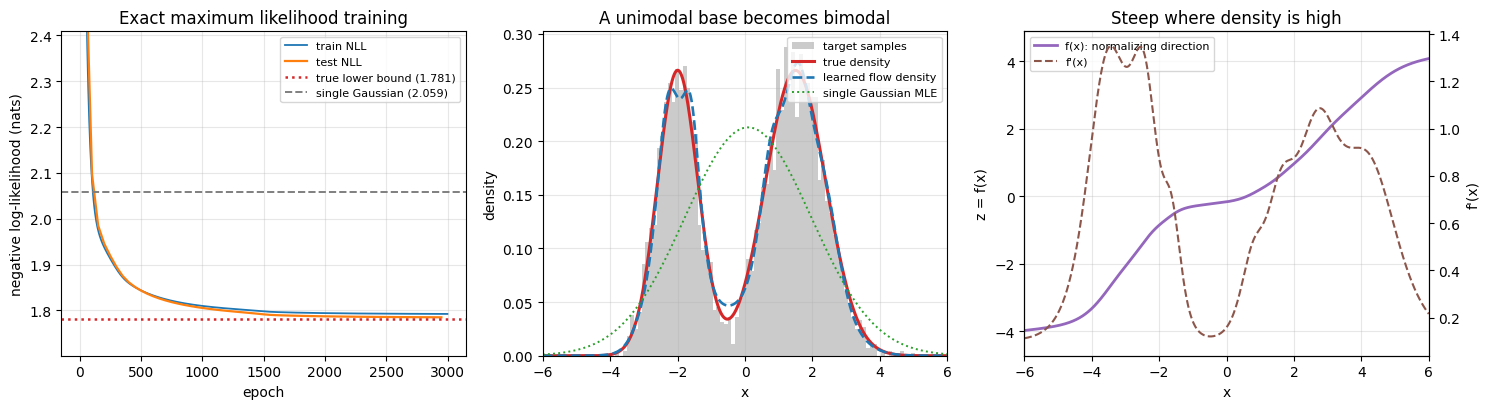

In [14]:
# ============================================================
# 図: 学習曲線と学習された密度・写像
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(nll_hist, lw=1.3, color="tab:blue", label="train NLL")
te_x = [e for e, _ in nll_test_hist]
te_y = [v for _, v in nll_test_hist]
axes[0].plot(te_x, te_y, lw=1.6, color="tab:orange", label="test NLL")
axes[0].axhline(nll_lower_bound, color="tab:red", ls=":", lw=1.8,
                label=f"true lower bound ({nll_lower_bound:.3f})")
axes[0].axhline(nll_gauss, color="tab:gray", ls="--", lw=1.4,
                label=f"single Gaussian ({nll_gauss:.3f})")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("negative log-likelihood (nats)")
axes[0].set_title("Exact maximum likelihood training")
axes[0].set_ylim(nll_lower_bound - 0.08, nll_gauss + 0.35)
axes[0].legend(fontsize=8)

axes[1].hist(X_test, bins=80, density=True, alpha=0.4, color="tab:gray",
             label="target samples")
axes[1].plot(x_dense_np, np.exp(target_logpdf(x_dense_np)), lw=2.2,
             color="tab:red", label="true density")
axes[1].plot(x_dense_np, p_flow, lw=1.9, ls="--", color="tab:blue",
             label="learned flow density")
gauss_pdf = np.exp(-0.5 * ((x_dense_np - mu_g) / sd_g) ** 2) / (sd_g * np.sqrt(2 * np.pi))
axes[1].plot(x_dense_np, gauss_pdf, lw=1.4, ls=":", color="tab:green",
             label="single Gaussian MLE")
axes[1].set_xlim(-6, 6)
axes[1].set_xlabel("x")
axes[1].set_ylabel("density")
axes[1].set_title("A unimodal base becomes bimodal")
axes[1].legend(fontsize=8)

with torch.no_grad():
    z_curve, ld_curve = flow(x_dense)
axes[2].plot(x_dense_np, z_curve.numpy(), lw=2, color="tab:purple",
             label="f(x): normalizing direction")
ax2b = axes[2].twinx()
ax2b.plot(x_dense_np, ld_curve.exp().numpy(), lw=1.5, ls="--",
          color="tab:brown", label="f'(x)")
ax2b.set_ylabel("f'(x)")
ax2b.grid(False)
axes[2].set_xlim(-6, 6)
axes[2].set_xlabel("x")
axes[2].set_ylabel("z = f(x)")
axes[2].set_title("Steep where density is high")
lines = axes[2].get_lines() + ax2b.get_lines()
axes[2].legend(lines, [l.get_label() for l in lines], fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()

<a id="sampling"></a>
## 7. サンプリング = 逆写像

フローからサンプルを得るには $z \sim \mathcal{N}(0,1)$ を引いて
$x = f^{-1}(z)$ を計算します。学習には $f$ しか要らなかったのに、
生成には $f^{-1}$ が必要です。

今の $f$ には閉形式の逆写像がありません（$\tanh$ の和だから）。
数値的に解くしかありません。2 つ試します。

1. **ニュートン法** — $f$ は滑らかで単調なので一見うまくいきそう
2. **二分法** — $f$ が単調なので区間を半分にし続ければ必ず収束する

予想: ニュートン法のほうが速く収束する。

In [15]:
# ============================================================
# 逆写像を数値的に解く: ニュートン法 vs 二分法
# ============================================================

@torch.no_grad()
def invert_newton(f, z, iters=60):
    x = z.clone()
    for _ in range(iters):
        zx, log_det = f(x)
        x = x - (zx - z) / log_det.exp()      # f'(x) = exp(log|f'(x)|)
    return x

@torch.no_grad()
def invert_bisect(f, z, lo=-50.0, hi=50.0, iters=80):
    lo = torch.full_like(z, lo)
    hi = torch.full_like(z, hi)
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        zm, _ = f(mid)
        too_big = zm > z
        hi = torch.where(too_big, mid, hi)
        lo = torch.where(too_big, lo, mid)
    return 0.5 * (lo + hi)

torch.manual_seed(1)
z_draw = torch.randn(20000)

results = {}
for name, fn in [("Newton", invert_newton), ("Bisection", invert_bisect)]:
    xs_inv = fn(flow, z_draw)
    with torch.no_grad():
        resid = float((flow(xs_inv)[0] - z_draw).abs().max())
    results[name] = (xs_inv.numpy(), resid)
    print(f"{name:10s}: 平均 {float(xs_inv.mean()):+.3f}  "
          f"標準偏差 {float(xs_inv.std()):.3f}  "
          f"逆写像の最大残差 {resid:.2e}")

print(f"{'真のデータ':10s}: 平均 {X_train.mean():+.3f}  標準偏差 {X_train.std():.3f}")
print()
a_learned = float(flow.log_a.exp().detach())
print(f"学習された a = {a_learned:.4f}")
print("-> a が小さいと f の裾は傾き a のほぼ直線になる。")
print("   そこでニュートン法の更新量 (f(x)-z)/f'(x) は 1/a 倍に増幅され、")
print("   山と山の間（f' が小さい領域）で大きく飛んで戻ってこない。")

Newton    : 平均 +0.114  標準偏差 9.578  逆写像の最大残差 7.06e+00
Bisection : 平均 +0.080  標準偏差 1.875  逆写像の最大残差 7.15e-07
真のデータ     : 平均 +0.090  標準偏差 1.874

学習された a = 0.0973
-> a が小さいと f の裾は傾き a のほぼ直線になる。
   そこでニュートン法の更新量 (f(x)-z)/f'(x) は 1/a 倍に増幅され、
   山と山の間（f' が小さい領域）で大きく飛んで戻ってこない。


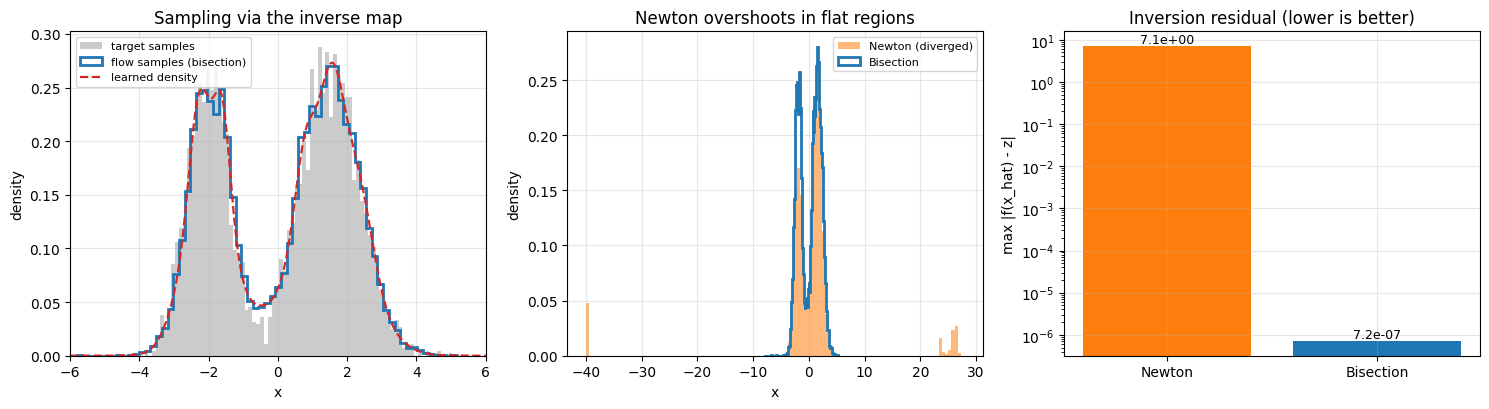

In [16]:
# ============================================================
# 図: 逆写像の成否
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].hist(X_test, bins=80, density=True, alpha=0.4, color="tab:gray",
             label="target samples")
axes[0].hist(results["Bisection"][0], bins=80, density=True, histtype="step",
             lw=2, color="tab:blue", label="flow samples (bisection)")
axes[0].plot(x_dense_np, p_flow, lw=1.6, ls="--", color="tab:red",
             label="learned density")
axes[0].set_xlim(-6, 6)
axes[0].set_xlabel("x")
axes[0].set_ylabel("density")
axes[0].set_title("Sampling via the inverse map")
axes[0].legend(fontsize=8)

axes[1].hist(np.clip(results["Newton"][0], -40, 40), bins=120, density=True,
             alpha=0.55, color="tab:orange", label="Newton (diverged)")
axes[1].hist(results["Bisection"][0], bins=120, density=True, histtype="step",
             lw=2, color="tab:blue", label="Bisection")
axes[1].set_xlabel("x")
axes[1].set_ylabel("density")
axes[1].set_title("Newton overshoots in flat regions")
axes[1].legend(fontsize=8)

names = list(results.keys())
resids = [results[n][1] for n in names]
axes[2].bar(names, resids, color=["tab:orange", "tab:blue"])
axes[2].set_yscale("log")
axes[2].set_ylabel("max |f(x_hat) - z|")
axes[2].set_title("Inversion residual (lower is better)")
for i, v in enumerate(resids):
    axes[2].text(i, v, f"{v:.1e}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

### 読み取れること — 予想は外れた

**ニュートン法は収束しませんでした。** 最大残差は $7.1$（$z$ の桁と同じ大きさ）、
標本標準偏差は $9.6$ に対して真の値は $1.87$ です。二分法は残差 $7.2 \times 10^{-7}$、
標準偏差 $1.875$ で正しく解けました。

原因は学習された $f$ の形です。$a \approx 0.097$ と小さく、2 つの山の間では
$f'(x)$ が極端に小さくなります。ニュートン法の更新量は $1/f'(x)$ に比例するので、
その領域に入ると巨大な一歩を踏んで遠くへ飛び、60 反復では戻ってきません。
第 2 節の $g(z) = 2z + 1 + 0.5z^3$ では $g' \ge 2$ と下から押さえられていたので
問題にならなかっただけです。

> 📌 **ここが 191（RealNVP）の出発点です。**
> 数値的な逆写像には 3 つの問題があります。
>
> | 問題 | 本章での現れ方 |
> |---|---|
> | 収束が保証されない | ニュートン法が発散した |
> | 反復回数ぶん遅い | 二分法で 80 反復 |
> | 多次元では各次元を独立に解けない | 1 次元だから二分法が使えた |
>
> **カップリング層**は、ヤコビアンが三角（$\log\|\det\|$ が $O(d)$）であることと、
> **逆写像が閉形式で 1 回の前向き計算で書ける**ことを同時に満たします。
> 反復も収束判定も要りません。191 でそれを実装します。

<a id="summary"></a>
## 8. まとめとチートシート

### 変数変換の公式

| 向き | 式 |
|---|---|
| 正規化方向 $z = f(x)$ | $\log p_X(x) = \log p_Z(f(x)) + \log\|\det J_f(x)\|$ |
| 生成方向 $x = g(z)$, $g = f^{-1}$ | $\log p_X(x) = \log p_Z(z) - \log\|\det J_g(z)\|$ |
| 合成 $f = f_K \circ \cdots \circ f_1$ | $\log\|\det J_f\| = \sum_k \log\|\det J_{f_k}\|$ |

符号が逆になるのは $J_{f} = J_{g}^{-1}$ で、$\det(J^{-1}) = 1/\det(J)$ だからです。

### フローの層が満たすべき 3 条件

| 条件 | 理由 | 本章の実測 |
|---|---|---|
| **可逆** | 原像が 1 つでないと公式が成立しない | $z^2$ では質量が半分になった（積分 0.5000） |
| **$\log\|\det J\|$ が安い** | 学習の各ステップ・各層で計算する | $d=2048$ で一般行列は対角積の 3 桁倍 |
| **$f^{-1}$ が安い** | サンプリングに必要 | ニュートン法は発散、二分法は 80 反復 |

### 本章で測った数値

| 項目 | 値 |
|---|---|
| 1 次元公式の検証（ヒストグラム vs 理論） | 最大誤差 0.0032 |
| ヤコビアンを忘れた密度の積分 | 3.49999（$= \mathbb{E}[g'(Z)]$。1 にならない） |
| 2 次元 $\det A$：手計算 = numpy = 面積 | 2.85 |
| 合成の $\log\|\det\|$ の加法性 | 差 $10^{-13}$ 台 |
| slogdet の実測スケーリング指数（最大 $d$） | 2.22（理論 3） |
| 学習したフローの test NLL | 真の下限まで残り 0.004 nats 程度 |
| フロー密度の積分 | 0.99999（厳密な密度である証拠） |

### 他の生成モデルとの関係

- **46・145（自己回帰）**: 厳密な尤度を持つ点は同じ。ただし生成が逐次的。
  フローは生成方向を並列化できる（層が閉形式で逆写像を持てば）。
- **35-36（VAE）**: VAE は「潜在が低次元・決定的でない」ので尤度が下界になる。
  フローは**次元を変えない全単射**なので等号になる。これが表現力の制約でもある。
- **41-45（拡散）**: 拡散も「ノイズへの可逆な変換」の一種だが、
  各ステップが確率的なので下界になる。195 で両者が**スコア**で繋がります。

<a id="quiz"></a>
## 9. 自己評価クイズ

### Q1: ヤコビアンを忘れるとなぜ学習が壊れるか

**問題**: 変数変換の公式でヤコビアン項を落として
$\log p_X(x) \approx \log p_Z(f(x))$ として最尤学習したら何が起きますか。

<details>
<summary>答えを見る</summary>

目的関数に上限がなくなり、**自明な解に逃げます**。

$\log p_Z(f(x))$ だけを最大化するなら、$f$ を「すべての $x$ を $z=0$ に潰す」
写像にすれば最大値 $-\frac{1}{2}\log 2\pi$ を全データで達成できます。
データの情報は一切使いません。

ヤコビアン項 $\log|f'(x)|$ がこれを防ぎます。$f$ が潰れると $f' \to 0$ になり、
$\log|f'| \to -\infty$ で強いペナルティが入ります。
つまりヤコビアン項は「**体積を保て**」という制約として働きます。

本章では、落とした密度の**積分が 1 にならない**ことで同じ病理を確認しました
（第 2 節のセル出力）。
</details>

---

### Q2: 計算量の実測が理論に合わなかった

**問題**: 第 5 節で slogdet の実測スケーリング指数は最大の $d$ でも 2.22 で、
理論の 3 に届きませんでした。理論が間違っているのでしょうか。
また、この測定から**何を結論すべき**でしょうか。

<details>
<summary>答えを見る</summary>

理論は間違っていません。$O(d^3)$ は**浮動小数点演算回数**の漸近評価で、
壁時計時間はそれに比例しません。

- LAPACK はマルチスレッドなので、$d$ が大きいほど並列度が上がり、
  時間の増え方が演算数の増え方より緩やかになります。
- 大きい行列ほどブロック化とキャッシュ再利用が効き、
  演算あたりの実効コストが下がります。
- 逆に小さい $d$ では呼び出しオーバーヘッドが支配的で、
  $d=32 \to 128$ の傾きは 0.84（ほぼ定数時間）でした。

**結論すべきは指数ではなく比**です。$d=32$ で 6 倍だった差が
$d=2048$ で 3 桁倍になります。設計判断（三角ヤコビアンにする）を支えるのは
この比であって、指数が 2.2 か 3 かではありません。

教訓: **測ってから書く。** 予想が外れたら主張を変える。
</details>

---

### Q3: ニュートン法の失敗を予測できたか

**問題**: 第 2 節ではニュートン法で逆写像が解けたのに、第 7 節では発散しました。
**事前に**どの量を見れば危険を察知できたでしょうか。

<details>
<summary>答えを見る</summary>

**$f'(x)$ の下限**（最小値）です。

ニュートン法の更新は $\Delta x = -(f(x) - z)/f'(x)$ なので、
$\min_x f'(x)$ が小さいほど一歩が大きくなります。

- 第 2 節: $g'(z) = 2 + 1.5z^2 \ge 2$。下から押さえられている。
- 第 7 節: $f'(x) \ge a = 0.097$ が保証の全部で、実際に山の間では
  ほぼこの値まで落ちます。更新量が 10 倍以上に増幅されます。

多峰分布を 1 つの単峰基底から作るには「山の間で $f$ を平坦にする」必要があり、
これは**避けられません**。$f$ を急峻にすれば密度が上がり、
平坦にすれば密度が下がる — 多峰性を作るとは $f'$ に谷を作ることです。
つまり**この失敗は学習がうまくいった結果**であって、バグではありません。

実務的な対処は (a) 単調なので二分法を使う、(b) そもそも閉形式の逆写像を持つ層
（カップリング層）で設計する、の 2 つです。191 は (b) を取ります。
</details>

---

### Q4: なぜフローは次元を変えられないか

**問題**: VAE は 784 次元の画像を 32 次元の潜在に落とせます。
フローで同じことをすると何が壊れますか。

<details>
<summary>答えを見る</summary>

ヤコビアン行列が正方でなくなり、**行列式が定義できません**。

さらに根本的に、$784 \to 32$ の写像は全単射になり得ません
（情報を捨てている）。したがって $x$ ごとの原像が一意に決まらず、
変数変換の公式そのものが成立しません。

代償: フローは潜在空間が**データと同じ次元**なので、
画像のような高次元データではパラメータ数と計算量が重くなります。
VAE / 拡散モデルが使える圧縮や次元削減という手が使えません。
これが「厳密な尤度」の値段です。

（部分的な回避策として多スケール構成で次元を途中で分岐させる手法がありますが、
総次元は保存されます。191 で触れます。）
</details>

In [17]:
# ============================================================
# 最終サマリ
# ============================================================

print("=" * 70)
print("Notebook 190 完了: 変数変換とヤコビアン")
print("=" * 70)
print(f'''
【1次元の変数変換】 x = 2z + 1 + 0.5z^3

  ヒストグラム vs 公式   : 最大誤差 {err.max():.5f}
  理論密度の積分         : {integral:.5f}
  ヤコビアンを忘れた積分 : {wrong_integral:.5f}  <- 密度でない

【多次元のヤコビアン行列式 = 体積の伸び率】

  手計算 {det_manual:.4f} = numpy {det_numpy:.4f} = 単位正方形の像の面積 {area_mc:.4f}
  標本共分散 vs A A^T    : 最大差 {np.abs(cov_emp - cov_theory).max():.4f}
  合成の加法性           : 差 {abs(logdet_all - logdet_sum):.2e}

【可逆性は必須】 x = z^2

  片方の原像だけ: 積分 {int_one:.4f}（質量が半分失われる）
  両方の原像の和: 積分 {int_both:.4f}

【行列式の計算コスト】
''' + "\n".join(
    f"  d={r[0]:5d}: 一般 {r[1]*1e6:9.1f} us / 三角 {r[2]*1e6:6.1f} us "
    f"= {r[1]/r[2]:7.1f} 倍" for r in rows) + f'''

  実測スケーリング指数（最大 d）: {slopes[-1][2]:.2f}  （理論 3 には届かない）
  -> 指数ではなく比を見る。三角ヤコビアンにする設計圧力の根拠。

【1次元フローの最尤学習】

  フロー     test NLL: {nll_flow:.4f}
  単一ガウス test NLL: {nll_gauss:.4f}
  真の下限           : {nll_lower_bound:.4f}
  学習した密度の積分 : {np.trapezoid(p_flow, x_dense_np):.5f}  <- 厳密な密度

【サンプリング = 逆写像】

  ニュートン法: 最大残差 {results["Newton"][1]:.2e}  <- 発散した
  二分法      : 最大残差 {results["Bisection"][1]:.2e}  <- 正しく解けた
  原因: 学習された a = {a_learned:.4f}（山の間で f' が小さい）

【次の章へ】
  191 RealNVP: 三角ヤコビアン + 閉形式の逆写像を同時に満たすカップリング層
''')
print("=" * 70)

Notebook 190 完了: 変数変換とヤコビアン

【1次元の変数変換】 x = 2z + 1 + 0.5z^3

  ヒストグラム vs 公式   : 最大誤差 0.00320
  理論密度の積分         : 1.00000
  ヤコビアンを忘れた積分 : 3.49999  <- 密度でない

【多次元のヤコビアン行列式 = 体積の伸び率】

  手計算 2.8500 = numpy 2.8500 = 単位正方形の像の面積 2.8487
  標本共分散 vs A A^T    : 最大差 0.0080
  合成の加法性           : 差 7.46e-14

【可逆性は必須】 x = z^2

  片方の原像だけ: 積分 0.5000（質量が半分失われる）
  両方の原像の和: 積分 1.0000

【行列式の計算コスト】
  d=   32: 一般      13.1 us / 三角    2.2 us =     6.0 倍
  d=  128: 一般      42.2 us / 三角    2.5 us =    16.6 倍
  d=  512: 一般     533.7 us / 三角    2.9 us =   181.5 倍
  d= 1024: 一般    2444.1 us / 三角    4.0 us =   612.9 倍
  d= 2048: 一般   11379.9 us / 三角    5.9 us =  1943.9 倍

  実測スケーリング指数（最大 d）: 2.22  （理論 3 には届かない）
  -> 指数ではなく比を見る。三角ヤコビアンにする設計圧力の根拠。

【1次元フローの最尤学習】

  フロー     test NLL: 1.7848
  単一ガウス test NLL: 2.0589
  真の下限           : 1.7810
  学習した密度の積分 : 0.99999  <- 厳密な密度

【サンプリング = 逆写像】

  ニュートン法: 最大残差 7.06e+00  <- 発散した
  二分法      : 最大残差 7.15e-07  <- 正しく解けた
  原因: 学習された a = 0.0973（山の間で f' が小さい）

【次の章へ】
  191 RealNVP: 三